# 09 — Modelo a fondo: random forest

**Objetivo:** entender el random forest (bosque aleatorio) lo suficiente como
para explicarlo y defender cada parámetro. Al terminar deberías poder explicar:
- cómo decide un **árbol de decisión** (preguntas de sí/no) y cómo elige cada
  pregunta (la **impureza de Gini**);
- por qué un árbol solo **sobreajusta** y qué hace `max_depth`;
- cómo el **bosque** corrige eso: muchos árboles distintos que votan;
- qué son `n_estimators`, `max_features`, `min_samples_leaf` y el error
  **out-of-bag**;
- por qué en cardíacos el bosque de la tesis tiene buen AUC pero especificidad
  casi nula, y qué tiene que ver `class_weight` con eso;
- cómo leer la **importancia** de las features (y sus límites);
- por qué un bosque puede **memorizar el caso** más que la regresión logística.

¿Por qué este modelo? Fue el mejor en cardíacos en la tesis, y es el
contrapunto natural de la regresión logística: no es lineal, no necesita
estandarizar y decide con reglas parecidas a un algoritmo clínico.

*(La notebook tarda unos 7 minutos en correr entera: entrena muchos bosques.)*

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.paths import OUT_DIR

NO_FEATURES = ["file_id", "label", "label_binary"]
SEMILLA = 0
# Con muy pocos árboles, el out-of-bag avisa que alguna grabación no quedó nunca afuera (sección 5)
warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores")


def cargar(subset):
    df = pd.read_csv(OUT_DIR / f"{subset.lower()}_features.csv")
    X, y = df.drop(columns=NO_FEATURES), df["label_binary"].values
    caso = df["file_id"].str.split("_").str[:2].str.join("_").values   # género_tipo
    return X, y, caso


datos = {s: cargar(s) for s in ["LS", "HS"]}
NOMBRE = {"LS": "Pulmonares", "HS": "Cardíacos"}


def bosque(**cambios):
    """El random forest de la tesis (Tabla 7.1), con los cambios que se pidan."""
    parametros = dict(n_estimators=300, class_weight="balanced", random_state=SEMILLA)
    parametros.update(cambios)
    return RandomForestClassifier(**parametros)


def prob_validacion(modelo, X, y, repeticiones=3):
    """Probabilidades out-of-fold (validación por grabación, 5 particiones), una lista por repetición."""
    return [cross_val_predict(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s),
                              method="predict_proba")[:, 1]
            for s in range(repeticiones)]


_ya_calculadas = {}


def prob_bosque(subset, **cambios):
    """prob_validacion del bosque de la tesis (con esos cambios) en un subconjunto.
    Guarda el resultado para no volver a entrenar los mismos bosques en otra sección."""
    clave = (subset, tuple(sorted(cambios.items())))
    if clave not in _ya_calculadas:
        X, y, caso = datos[subset]
        _ya_calculadas[clave] = prob_validacion(bosque(**cambios), X, y)
    return _ya_calculadas[clave]


def metricas(y, probs, umbral=0.5):
    """AUC, sensibilidad y especificidad (con ese umbral), promediadas entre repeticiones."""
    filas = []
    for p in probs:
        tn, fp, fn, tp = confusion_matrix(y, p >= umbral).ravel()
        filas.append({"AUC": roc_auc_score(y, p), "sensibilidad": tp / (tp + fn),
                      "especificidad": tn / (tn + fp)})
    return pd.DataFrame(filas).mean()

## 1. Un árbol de decisión: preguntas de sí o no

Un árbol de decisión clasifica haciendo **preguntas sucesivas** sobre las
features, del tipo *"¿esta feature es menor o igual a tal valor?"*. Según la
respuesta, la grabación baja por la rama izquierda (sí) o la derecha (no),
hasta llegar a una **hoja**, que da la respuesta.

Es la misma lógica que un algoritmo clínico (las reglas de Ottawa para el
tobillo, un algoritmo de triage): preguntas de sí o no en orden. La diferencia
es que acá **el árbol elige solo** qué preguntar y dónde poner cada corte,
mirando los datos.

Entrenamos un árbol chiquito (2 niveles de preguntas) con todas las
grabaciones pulmonares, solo para mirarlo:

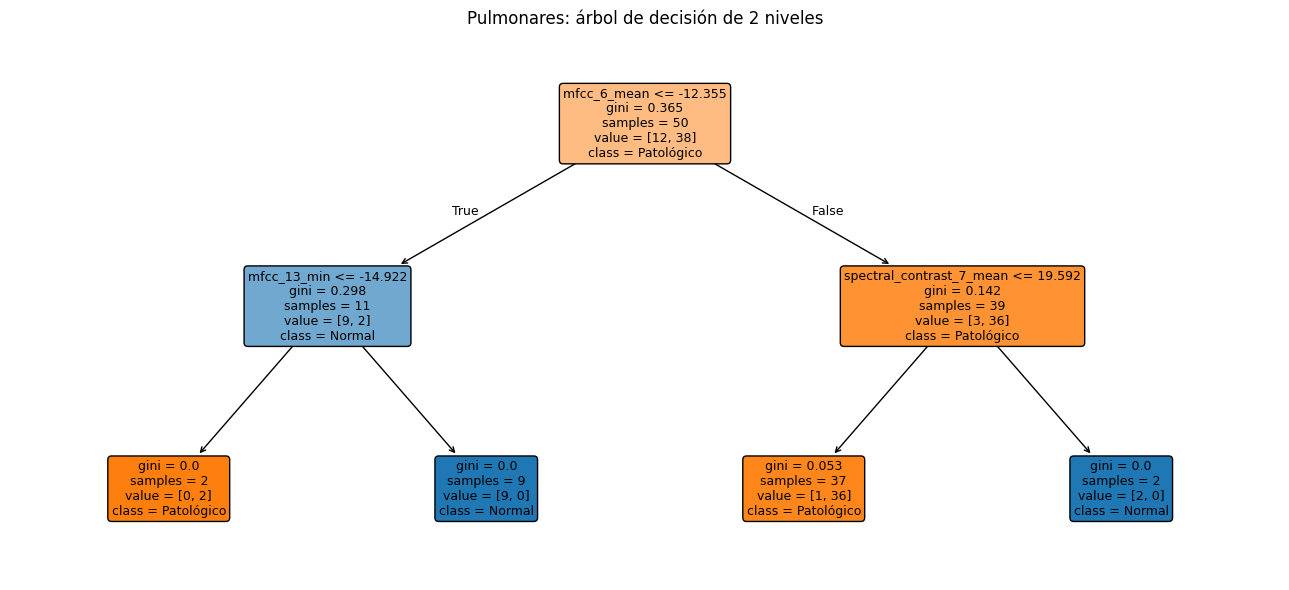

In [2]:
X_ls, y_ls, caso_ls = datos["LS"]
arbol = DecisionTreeClassifier(max_depth=2, random_state=SEMILLA).fit(X_ls, y_ls)

fig, ax = plt.subplots(figsize=(13, 6))
cajas = plot_tree(arbol, feature_names=list(X_ls.columns), class_names=["Normal", "Patológico"],
                  filled=True, impurity=True, rounded=True, fontsize=9, ax=ax)
# Colores como en el resto de las notebooks: azul = normal, naranja = patológico (más intenso = más puro)
for nodo, caja in enumerate(c for c in cajas if c.get_bbox_patch() is not None):
    p = arbol.tree_.value[nodo, 0, 1] / arbol.tree_.value[nodo, 0].sum()
    base = np.array(to_rgb("tab:orange" if p >= 0.5 else "tab:blue"))
    intensidad = abs(2 * p - 1)
    caja.get_bbox_patch().set_facecolor(intensidad * base + (1 - intensidad))
ax.set_title("Pulmonares: árbol de decisión de 2 niveles")
fig.tight_layout()

**Cómo leer cada caja:**
- **primera línea:** la pregunta (si la respuesta es sí, se va a la izquierda);
- **gini:** qué tan mezcladas están las clases en esa caja (sección 2);
- **samples:** cuántas grabaciones llegan ahí;
- **value:** cuántas son normales y cuántas patológicas, en ese orden;
- **class:** la clase mayoritaria, que es lo que la caja respondería.

El color indica la clase mayoritaria (azul: normal; naranja: patológico) y
su intensidad, qué tan "pura" es la caja.

La **probabilidad** que da el árbol para una grabación nueva es la proporción
de patológicos en la hoja a la que llega. Si cae en una hoja con 30
patológicos y 0 normales, la probabilidad es 1.

**Un detalle práctico:** el árbol solo compara cada feature con un umbral, así
que únicamente le importa el **orden** de los valores. Por eso **no hace falta
estandarizar** (a diferencia de la regresión logística).

## 2. Cómo elige cada pregunta: la impureza de Gini

Una buena pregunta es la que **separa mejor las clases**: que después de
responderla, cada lado quede lo más "puro" posible (casi todo normal o casi
todo patológico).

Para medir qué tan mezclada está una caja se usa la **impureza de Gini**. Si
en la caja hay una proporción *p* de patológicos:

$$\text{Gini} = 1 - p^2 - (1-p)^2 = 2\,p\,(1-p)$$

- vale **0** si la caja es pura (todo de una clase);
- vale **0,5** si es mitad y mitad (lo más mezclado posible).

Una forma de pensarlo: es la probabilidad de equivocarse si a una grabación de
esa caja le asignamos una etiqueta al azar, respetando las proporciones de la
caja.

Para elegir la primera pregunta, el árbol **prueba todas las features y todos
los cortes posibles** y se queda con el que más baja la impureza (el promedio
de la impureza de los dos lados, ponderado por cuántas grabaciones van a cada
lado). Hagamos la cuenta para la primera pregunta del árbol de arriba:

In [3]:
def gini(etiquetas):
    p = np.mean(etiquetas)
    return 2 * p * (1 - p)


feature_raiz = X_ls.columns[arbol.tree_.feature[0]]
corte_raiz = arbol.tree_.threshold[0]
izquierda = y_ls[X_ls[feature_raiz] <= corte_raiz]
derecha = y_ls[X_ls[feature_raiz] > corte_raiz]
promedio = (len(izquierda) * gini(izquierda) + len(derecha) * gini(derecha)) / len(y_ls)

print(f"Pregunta: ¿{feature_raiz} <= {corte_raiz:.2f}?")
print(f"Antes de preguntar: {(y_ls == 0).sum()} normales y {(y_ls == 1).sum()} patológicos, Gini = {gini(y_ls):.3f}")
print(f"Lado 'sí':  {(izquierda == 0).sum()} normales y {(izquierda == 1).sum()} patológicos, Gini = {gini(izquierda):.3f}")
print(f"Lado 'no':  {(derecha == 0).sum()} normales y {(derecha == 1).sum()} patológicos, Gini = {gini(derecha):.3f}")
print(f"Gini promedio después de preguntar: {promedio:.3f}  (bajó {gini(y_ls) - promedio:.3f})")

Pregunta: ¿mfcc_6_mean <= -12.36?
Antes de preguntar: 12 normales y 38 patológicos, Gini = 0.365
Lado 'sí':  9 normales y 2 patológicos, Gini = 0.298
Lado 'no':  3 normales y 36 patológicos, Gini = 0.142
Gini promedio después de preguntar: 0.176  (bajó 0.189)


Y así eligió **dónde cortar**: probó todos los cortes posibles de esa feature
(y de las otras 104) y se quedó con el que más bajaba la impureza.

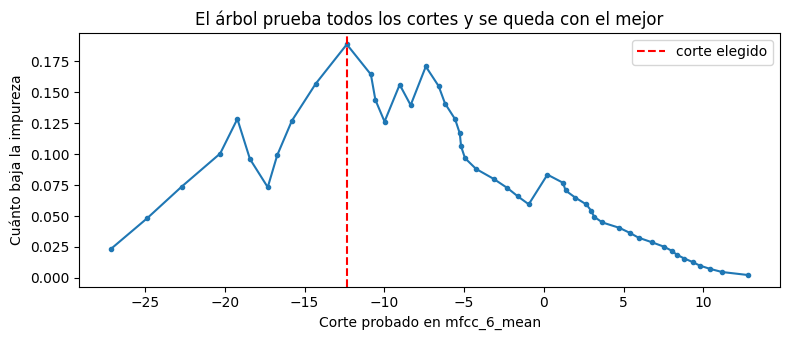

In [4]:
valores = np.sort(X_ls[feature_raiz].unique())
cortes = (valores[:-1] + valores[1:]) / 2
mejora = []
for c in cortes:
    izq, der = y_ls[X_ls[feature_raiz] <= c], y_ls[X_ls[feature_raiz] > c]
    mejora.append(gini(y_ls) - (len(izq) * gini(izq) + len(der) * gini(der)) / len(y_ls))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cortes, mejora, "o-", ms=3)
ax.axvline(corte_raiz, color="red", ls="--", label="corte elegido")
ax.set(xlabel=f"Corte probado en {feature_raiz}", ylabel="Cuánto baja la impureza",
       title="El árbol prueba todos los cortes y se queda con el mejor")
ax.legend()
fig.tight_layout()

Después repite lo mismo **dentro de cada lado**, por separado: busca la mejor
pregunta para las grabaciones que respondieron "sí" y la mejor para las que
respondieron "no". Y así sucesivamente.

## 3. ¿Hasta dónde crece? Profundidad y sobreajuste

Si no se le pone un límite, el árbol sigue preguntando hasta que **todas las
hojas son puras**. Con 50 grabaciones eso siempre se puede lograr, así que en
entrenamiento acierta todo:

In [5]:
for subset, (X, y, caso) in datos.items():
    completo = DecisionTreeClassifier(random_state=SEMILLA).fit(X, y)
    print(f"{NOMBRE[subset]}: árbol sin límite con {completo.get_depth()} niveles y "
          f"{completo.get_n_leaves()} hojas; AUC en entrenamiento = "
          f"{roc_auc_score(y, completo.predict_proba(X)[:, 1]):.2f}")

Pulmonares: árbol sin límite con 3 niveles y 5 hojas; AUC en entrenamiento = 1.00
Cardíacos: árbol sin límite con 4 niveles y 5 hojas; AUC en entrenamiento = 1.00


Acertar todo en entrenamiento no dice nada (notebook 07). Veamos el AUC en
validación cruzada según la profundidad máxima (`max_depth`):

In [6]:
filas = []
for subset, (X, y, caso) in datos.items():
    for profundidad in [1, 2, 3, 4, None]:
        modelo = DecisionTreeClassifier(max_depth=profundidad, class_weight="balanced", random_state=SEMILLA)
        filas.append({"subconjunto": NOMBRE[subset], "max_depth": profundidad or "sin límite",
                      **metricas(y, prob_validacion(modelo, X, y, repeticiones=10))})
print(pd.DataFrame(filas).round(2).to_string(index=False))

subconjunto  max_depth  AUC  sensibilidad  especificidad
 Pulmonares          1 0.71          0.71           0.72
 Pulmonares          2 0.76          0.89           0.65
 Pulmonares          3 0.75          0.90           0.61
 Pulmonares          4 0.75          0.90           0.61
 Pulmonares sin límite 0.75          0.90           0.61
  Cardíacos          1 0.67          0.68           0.70
  Cardíacos          2 0.59          0.80           0.38
  Cardíacos          3 0.57          0.83           0.30
  Cardíacos          4 0.56          0.85           0.28
  Cardíacos sin límite 0.56          0.85           0.28


**Cómo leerlo:** en cardíacos, **cuanto más profundo, peor** en validación:
cada pregunta extra se adapta más a las grabaciones particulares de
entrenamiento (sobreajuste). En pulmonares, a partir de 2 niveles da igual
(el árbol ya separa todo y deja de crecer). Un árbol solo tiene **varianza
alta**: con otra muestra, aprendería preguntas muy distintas.

Lo vemos directamente: entrenamos el mismo árbol con 5 remuestreos bootstrap
de las grabaciones cardíacas y miramos cuál es su **primera** pregunta:

In [7]:
X_hs, y_hs, caso_hs = datos["HS"]
rng = np.random.default_rng(SEMILLA)
for i in range(5):
    m = rng.integers(0, len(y_hs), len(y_hs))
    a = DecisionTreeClassifier(random_state=SEMILLA).fit(X_hs.iloc[m], y_hs[m])
    print(f"Remuestreo {i + 1}: ¿{X_hs.columns[a.tree_.feature[0]]} <= {a.tree_.threshold[0]:.2f}?")

Remuestreo 1: ¿mfcc_delta_5_std <= 1.90?
Remuestreo 2: ¿mfcc_5_mean <= 22.74?
Remuestreo 3: ¿mfcc_4_max <= 71.25?
Remuestreo 4: ¿mfcc_4_std <= 7.91?
Remuestreo 5: ¿mfcc_4_max <= 68.67?


Pequeños cambios en los datos cambian la primera pregunta, y con ella todo
el árbol. Esa inestabilidad es justamente lo que el bosque aprovecha.

## 4. Del árbol al bosque

Un **random forest** entrena **muchos árboles distintos** y promedia sus
respuestas. Para que sean distintos, introduce dos fuentes de azar:

1. **Cada árbol ve una muestra distinta** de grabaciones: un remuestreo
   bootstrap (50 al azar con reposición; algunas salen repetidas y otras no
   salen). Esto se llama *bagging*.
2. **En cada pregunta, cada árbol solo puede elegir entre unas pocas features
   sorteadas** (por defecto, √105 ≈ 10 de las 105). Así no todos los árboles
   preguntan primero por la misma feature dominante.

La probabilidad del bosque es el **promedio** de las probabilidades de sus
árboles. Como cada árbol crece hasta tener hojas puras, en la práctica es la
**fracción de árboles que votan "patológico"**.

**¿Por qué funciona?** Cada árbol solo es inestable (varianza alta), pero sus
errores son en buena parte distintos entre sí, y al promediar se compensan.
Es como pedirle opinión a 300 colegas que vieron pacientes distintos y se
fijan en signos distintos: cada uno solo puede equivocarse bastante, pero el
promedio de sus opiniones es mucho más estable. El sorteo de features sirve
para que los "colegas" no piensen todos igual: si todos miraran lo mismo,
promediarlos no ayudaría.

In [8]:
filas = []
for subset, (X, y, caso) in datos.items():
    un_arbol = DecisionTreeClassifier(class_weight="balanced", random_state=SEMILLA)
    filas.append({"subconjunto": NOMBRE[subset], "modelo": "un árbol sin límite",
                  "AUC (validación)": metricas(y, prob_validacion(un_arbol, X, y))["AUC"]})
    filas.append({"subconjunto": NOMBRE[subset], "modelo": "bosque de 300 árboles",
                  "AUC (validación)": metricas(y, prob_bosque(subset))["AUC"]})
print(pd.DataFrame(filas).round(3).to_string(index=False))

subconjunto                modelo  AUC (validación)
 Pulmonares   un árbol sin límite             0.730
 Pulmonares bosque de 300 árboles             0.949
  Cardíacos   un árbol sin límite             0.583
  Cardíacos bosque de 300 árboles             0.785


Los mismos árboles que solos sobreajustan, juntos funcionan mucho mejor. Fijate
que en el bosque los árboles **no se podan**: cada uno crece hasta el final y
sobreajusta. El bosque no evita el sobreajuste de cada árbol: lo **promedia**.

## 5. `n_estimators` y el error out-of-bag

`n_estimators` es la **cantidad de árboles**. La tesis usa 300.

Como cada árbol se entrena con un remuestreo bootstrap, **cada árbol no ve
alrededor de un tercio de las grabaciones** (en promedio, el 37 %). Para cada
grabación se puede calcular entonces la predicción **solo con los árboles que
no la vieron**: es la predicción **out-of-bag** ("fuera de la bolsa"). Es una
validación que viene gratis con el bosque, sin separar datos aparte.

Veamos cómo cambia el AUC out-of-bag al agregar árboles, con tres semillas
distintas:

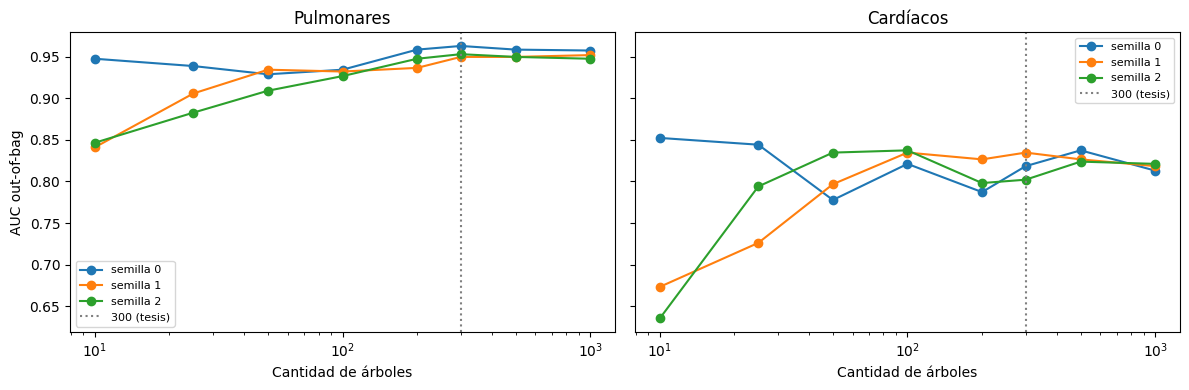

In [9]:
CANTIDADES = [10, 25, 50, 100, 200, 300, 500, 1000]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (subset, (X, y, caso)) in zip(axes, datos.items()):
    for semilla in range(3):
        aucs = []
        for n in CANTIDADES:
            m = bosque(n_estimators=n, oob_score=True, random_state=semilla).fit(X, y)
            p = m.oob_decision_function_[:, 1]
            visto = ~np.isnan(p)   # con muy pocos árboles, alguna grabación puede no quedar nunca afuera
            aucs.append(roc_auc_score(y[visto], p[visto]))
        ax.plot(CANTIDADES, aucs, "o-", label=f"semilla {semilla}")
    ax.axvline(300, color="gray", ls=":", label="300 (tesis)")
    ax.set(xscale="log", xlabel="Cantidad de árboles", title=NOMBRE[subset])
    ax.legend(fontsize=8)
axes[0].set_ylabel("AUC out-of-bag")
fig.tight_layout()

**Cómo leerlo:** con pocos árboles, el resultado depende mucho de la semilla
(las líneas se separan); con más árboles, las líneas se juntan y se
estabilizan. **Agregar árboles no produce sobreajuste**: solo promedia más
opiniones. El único costo es el tiempo de cálculo. Por eso `n_estimators` no
se "ajusta": se elige un número suficientemente grande, y 300 alcanza.

**Ojo:** el out-of-bag es una validación **por grabación**, igual que la
validación cruzada estratificada: las grabaciones "hermanas" del mismo caso
pueden estar dentro de la bolsa.

## 6. Los otros hiperparámetros: `max_features`, `min_samples_leaf`, `max_depth`

| Parámetro | Valor por defecto (el de la tesis) | Qué controla |
|---|---|---|
| `max_features` | `"sqrt"`: √105 ≈ 10 features por pregunta | cuánto se parecen los árboles entre sí (menos features = árboles más distintos) |
| `min_samples_leaf` | 1 | cuántas grabaciones tiene que tener, como mínimo, cada hoja (1 = árboles completos) |
| `max_depth` | sin límite | cuántos niveles de preguntas puede tener cada árbol |

Veamos cuánto cambian el resultado:

In [10]:
VARIANTES = {
    "tesis (max_features=sqrt, min_samples_leaf=1)": {},
    "max_features=0.3 (≈32 features)": {"max_features": 0.3},
    "max_features=1.0 (todas)": {"max_features": 1.0},
    "min_samples_leaf=3": {"min_samples_leaf": 3},
    "min_samples_leaf=5": {"min_samples_leaf": 5},
    "max_depth=3": {"max_depth": 3},
}
filas = []
for subset, (X, y, caso) in datos.items():
    for nombre, cambios in VARIANTES.items():
        filas.append({"subconjunto": NOMBRE[subset], "variante": nombre,
                      **metricas(y, prob_bosque(subset, **cambios))})
print(pd.DataFrame(filas).round(2).to_string(index=False))

subconjunto                                      variante  AUC  sensibilidad  especificidad
 Pulmonares tesis (max_features=sqrt, min_samples_leaf=1) 0.95          0.99           0.64
 Pulmonares               max_features=0.3 (≈32 features) 0.95          0.99           0.64
 Pulmonares                      max_features=1.0 (todas) 0.93          0.99           0.61
 Pulmonares                            min_samples_leaf=3 0.94          0.99           0.67
 Pulmonares                            min_samples_leaf=5 0.94          0.97           0.67
 Pulmonares                                   max_depth=3 0.95          0.99           0.64
  Cardíacos tesis (max_features=sqrt, min_samples_leaf=1) 0.79          0.98           0.07
  Cardíacos               max_features=0.3 (≈32 features) 0.80          0.98           0.00
  Cardíacos                      max_features=1.0 (todas) 0.79          0.93           0.11
  Cardíacos                            min_samples_leaf=3 0.79          0.96    

**Cómo leerlo:**
- El **AUC** cambia poco entre variantes: el bosque es bastante robusto a sus
  hiperparámetros (a diferencia del árbol solo, o de C en la regresión
  logística en cardíacos).
- Lo que sí cambia, y mucho, es la **especificidad** en cardíacos. Eso es lo
  que explica la sección siguiente.

Igual que con C en la notebook 08: **esta tabla no sirve para elegir** la
mejor variante y reportarla; sería elegir mirando los resultados. Si se cambia
algo, tiene que ser con un argumento previo o con validación anidada.

## 7. El misterio de la especificidad en cardíacos

En la tesis, el bosque con `class_weight` en cardíacos tuvo el **mejor AUC**
de todos los modelos (0,84), pero con **sensibilidad 0,98 y especificidad
0,11**: dice "patológico" a casi todo, incluidos casi todos los normales.
¿Cómo puede un modelo ordenar bien y a la vez clasificar mal?

*(Los AUC de esta notebook no coinciden exactamente con la tabla de la tesis:
allí se promediaba el AUC de cada partición; acá, como en la notebook 07, se
calcula una sola vez con todas las probabilidades out-of-fold juntas, que con
tan pocos normales por partición es más estable. La conclusión es la misma.)*

Miremos las probabilidades out-of-fold que les da el bosque a las grabaciones
cardíacas:

Probabilidades de los 9 normales: [0.55 0.57 0.59 0.64 0.67 0.75 0.8  0.88 0.89]
Mediana de los patológicos: 0.89


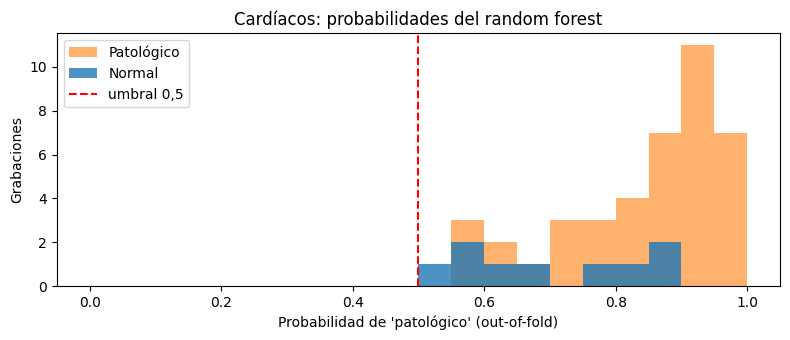

In [11]:
prob_hs = np.mean(prob_bosque("HS"), axis=0)   # promedio de las 3 repeticiones

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 21)
ax.hist(prob_hs[y_hs == 1], bins=bins, alpha=0.6, color="tab:orange", label="Patológico")
ax.hist(prob_hs[y_hs == 0], bins=bins, alpha=0.8, color="tab:blue", label="Normal")
ax.axvline(0.5, color="red", ls="--", label="umbral 0,5")
ax.set(xlabel="Probabilidad de 'patológico' (out-of-fold)", ylabel="Grabaciones",
       title="Cardíacos: probabilidades del random forest")
ax.legend()
fig.tight_layout()
print("Probabilidades de los 9 normales:", np.round(np.sort(prob_hs[y_hs == 0]), 2))
print("Mediana de los patológicos:", round(np.median(prob_hs[y_hs == 1]), 2))

**Todos los normales quedan por encima de 0,5.** Pero quedan, en general, más
abajo que los patológicos: el bosque **los ordena bien** (por eso el AUC es
bueno), solo que **toda la escala está corrida hacia arriba**. Es la lección
de la notebook 06: el AUC mide el orden y no depende del umbral; la
sensibilidad y la especificidad sí.

**¿Por qué está corrida la escala?** Porque 41 de las 50 grabaciones cardíacas
son patológicas. En cada árbol, la mayoría de las hojas son "patológicas", y
una grabación normal nueva suele caer en alguna de ellas. La fracción de
árboles que votan "patológico" queda alta para casi todos.

**¿Y `class_weight="balanced"` no debería corregir eso?** En la regresión
logística sí, porque cambia cuánto pesa cada error. Pero en un bosque con
árboles completos (`min_samples_leaf=1`), cada hoja termina **pura**: una hoja
con 3 patológicos y 0 normales vota "patológico" con probabilidad 1, pesen lo
que pesen los patológicos. El peso de las clases solo influye en **qué
preguntas** se eligen, no en el voto final de las hojas. Comparemos:

In [12]:
OPCIONES = {
    "sin class_weight": {"class_weight": None},
    "class_weight='balanced' (tesis)": {},
    "class_weight='balanced_subsample'": {"class_weight": "balanced_subsample"},
    "balanced + min_samples_leaf=5": {"min_samples_leaf": 5},
}
filas = []
for subset, (X, y, caso) in datos.items():
    for nombre, cambios in OPCIONES.items():
        filas.append({"subconjunto": NOMBRE[subset], "opción": nombre,
                      **metricas(y, prob_bosque(subset, **cambios))})
print(pd.DataFrame(filas).round(2).to_string(index=False))

subconjunto                            opción  AUC  sensibilidad  especificidad
 Pulmonares                  sin class_weight 0.96          1.00           0.53
 Pulmonares   class_weight='balanced' (tesis) 0.95          0.99           0.64
 Pulmonares class_weight='balanced_subsample' 0.95          0.99           0.61
 Pulmonares     balanced + min_samples_leaf=5 0.94          0.97           0.67
  Cardíacos                  sin class_weight 0.78          0.98           0.07
  Cardíacos   class_weight='balanced' (tesis) 0.79          0.98           0.07
  Cardíacos class_weight='balanced_subsample' 0.81          0.98           0.07
  Cardíacos     balanced + min_samples_leaf=5 0.78          0.89           0.37


**Cómo leerlo:**
- En **cardíacos**, con o sin `class_weight` la especificidad es
  prácticamente la misma: con árboles completos, **el peso de las clases casi
  no actúa**. En pulmonares ayuda algo, porque cambia qué preguntas se eligen,
  pero no puede cambiar el voto de las hojas.
- `balanced_subsample` (recalcula los pesos en cada remuestreo) tampoco lo
  resuelve, por la misma razón.
- Con `min_samples_leaf=5`, las hojas ya no son puras (tienen al menos 5
  grabaciones), y ahí el peso de las clases **sí** cambia el voto de cada
  hoja: la escala baja y la especificidad sube, con un AUC parecido.
- En la tesis, con **SMOTE** la especificidad del bosque fue 0,47: al
  entrenar con clases equilibradas (con normales sintéticos), aparecen más
  hojas "normales".

**Otra salida: mover el umbral.** Si el orden es bueno, se puede buscar un
umbral más alto que 0,5. Mirá cómo cambian la sensibilidad y la especificidad:

In [13]:
print(pd.DataFrame({u: metricas(y_hs, prob_bosque("HS"), umbral=u) for u in [0.5, 0.6, 0.7, 0.8, 0.9]}
                   ).T.round(2).rename_axis("umbral").to_string())

         AUC  sensibilidad  especificidad
umbral                                   
0.5     0.79          0.98           0.07
0.6     0.79          0.93           0.26
0.7     0.79          0.85           0.52
0.8     0.79          0.72           0.67
0.9     0.79          0.50           0.89


Subiendo el umbral se gana especificidad a costa de sensibilidad (moverse por
la curva ROC). Pero, otra vez, **el umbral no se puede elegir mirando esta
tabla**: tendría que elegirse dentro de la validación cruzada (con los datos
de entrenamiento de cada partición), o fijarse de antemano con un criterio
clínico (por ejemplo, "sensibilidad de al menos 0,90 para tamizaje").

**Para la tesis:** el bosque es el que mejor **ordena** en cardíacos, pero con
el umbral 0,5 y `class_weight` es inútil para descartar: casi no reconoce a
los normales. Comparar modelos solo por AUC escondía este problema. En la
notebook 11 se reportan sensibilidad y especificidad para todos.

## 8. Importancia de las features

El bosque no tiene coeficientes, pero da una **importancia** por feature:
cuánto bajó la impureza de Gini, en total, cada vez que alguna pregunta usó
esa feature, promediado entre los 300 árboles (y normalizado para que todas
sumen 1). Se la llama "importancia por disminución de impureza" (*MDI*).

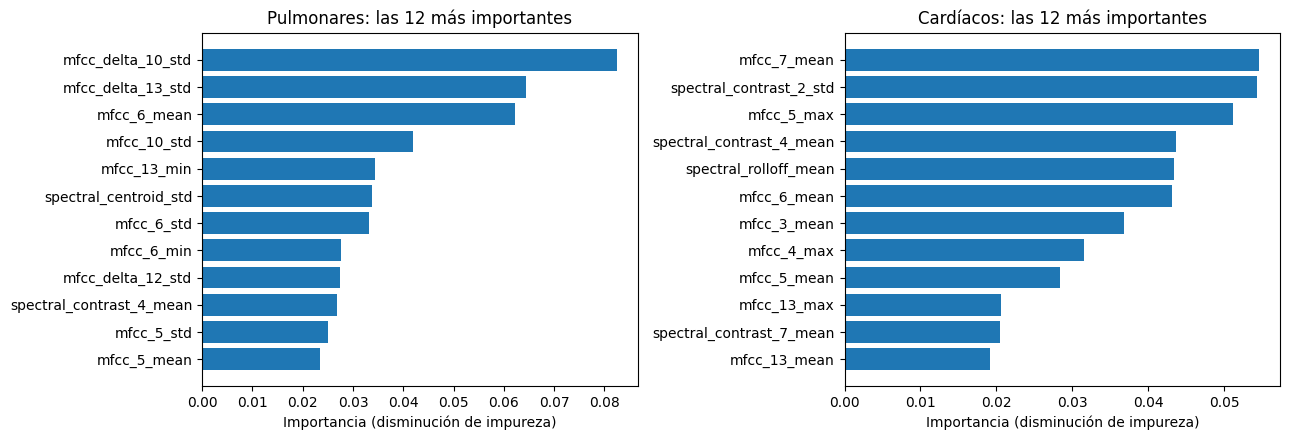

In [14]:
def importancias(X, y, **cambios):
    return pd.Series(bosque(**cambios).fit(X, y).feature_importances_, index=X.columns)


imp_ls = importancias(X_ls, y_ls).sort_values(ascending=False)
imp_hs = importancias(X_hs, y_hs).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (subset, imp) in zip(axes, [("LS", imp_ls), ("HS", imp_hs)]):
    top = imp.head(12)
    ax.barh(top.index[::-1], top.values[::-1])
    ax.set(xlabel="Importancia (disminución de impureza)", title=f"{NOMBRE[subset]}: las 12 más importantes")
fig.tight_layout()

**Cómo leerla, y sus límites:**
1. **No tiene signo.** Dice cuánto usa el bosque una feature, no si valores
   altos empujan hacia "patológico" o hacia "normal" (el peso de la regresión
   logística sí lo decía).
2. **Features correlacionadas se reparten la importancia**, igual que se
   repartían el peso en la regresión logística. Una feature puede parecer poco
   importante solo porque tiene una "gemela" que el bosque usó en su lugar.
3. **Se calcula con los datos de entrenamiento.** Con árboles completos, el
   bosque también usa features para memorizar detalles, y eso suma
   importancia aunque no ayude a predecir grabaciones nuevas. La alternativa
   más honesta es la **importancia por permutación sobre datos de
   validación**: mezclar al azar los valores de una feature y medir cuánto
   empeora el AUC.
4. **Asociación, no causa**, como siempre.

¿Es estable? Repetimos con 20 remuestreos bootstrap y contamos en qué
fracción de ellos cada feature del top 10 vuelve a aparecer en el top 10:

In [15]:
def estabilidad_top10(X, y, top, n=20):
    rng = np.random.default_rng(SEMILLA)
    cuenta = pd.Series(0, index=X.columns)
    for _ in range(n):
        m = rng.integers(0, len(y), len(y))
        cuenta[importancias(X.iloc[m], y[m]).nlargest(10).index] += 1
    return (cuenta[top] / n).round(2)


print("Pulmonares:", estabilidad_top10(X_ls, y_ls, imp_ls.head(10).index).to_string(), sep="\n")
print("\nCardíacos:", estabilidad_top10(X_hs, y_hs, imp_hs.head(10).index).to_string(), sep="\n")

Pulmonares:
mfcc_delta_10_std           1.00
mfcc_delta_13_std           0.90
mfcc_6_mean                 0.90
mfcc_10_std                 0.60
mfcc_13_min                 0.75
spectral_centroid_std       0.45
mfcc_6_std                  0.25
mfcc_6_min                  0.00
mfcc_delta_12_std           0.65
spectral_contrast_4_mean    0.25

Cardíacos:
mfcc_7_mean                 0.75
spectral_contrast_2_std     0.60
mfcc_5_max                  0.70
spectral_contrast_4_mean    0.50
spectral_rolloff_mean       0.30
mfcc_6_mean                 0.55
mfcc_3_mean                 0.55
mfcc_4_max                  0.60
mfcc_5_mean                 0.75
mfcc_13_max                 0.25


**Cómo leerlo:**
- En **pulmonares**, las tres primeras (`mfcc_delta_10_std`,
  `mfcc_delta_13_std` y `mfcc_6_mean`) vuelven a aparecer en el top 10 en
  casi todos los remuestreos: el bosque las usa de forma consistente. Además
  coinciden con la regresión logística: `mfcc_delta_10_std` era la mejor
  feature sola y `mfcc_6_mean` estaba entre los pesos más grandes (notebook
  08). Que dos modelos tan distintos se apoyen en lo mismo es una buena señal.
- En **cardíacos**, ninguna aparece en todos los remuestreos: la lista de
  "importantes" cambia bastante con los datos, otra muestra de lo débil que
  es la señal cardíaca. Y entre las más importantes vuelven a aparecer
  **máximos de MFCC** (`mfcc_5_max`, `mfcc_4_max`...), los mismos sospechosos
  de las tramas del borde (notebook 03, sección 9.1).

## 9. ¿El bosque memoriza el caso?

En la notebook 07 vimos que una grabación tiene "hermanas" (el mismo caso del
maniquí en otra localización o con otro género), y que validar por grabación
puede dejar una hermana en entrenamiento. Con la regresión logística, esa
fuga resultó chica en pulmonares (~0,02 de AUC) y nula en cardíacos.

Hay una razón para sospechar que en el bosque la fuga es **mayor**. Con
árboles completos, cada hoja termina conteniendo una o muy pocas grabaciones
de entrenamiento. Una grabación nueva casi idéntica a su hermana cae **en la
misma hoja que ella** en muchos árboles, y recibe su etiqueta: el bosque se
comporta, en parte, como "buscar la grabación de entrenamiento más parecida y
copiar su respuesta". La regresión logística no puede hacer eso: ajusta una
sola frontera para todos.

Repetimos el control de la notebook 07 con el bosque de la tesis: validación
por grabación, por pseudo-caso (grupos al azar del mismo tamaño y clase, 6
sorteos) y por caso real. Como el bosque tiene su propio azar, el caso real
lo calculamos con 3 semillas distintas del bosque, para ver cuánto cambia
solo por eso.

*(Este experimento entrena casi 300 bosques: tarda un par de minutos.)*

In [16]:
def pseudo_casos(caso, y, rng):
    """Grupos al azar con los mismos tamaños y la misma clase que los casos reales (notebook 07)."""
    nuevo = np.empty(len(caso), dtype=object)
    for clase in [0, 1]:
        indices = rng.permutation(np.where(y == clase)[0])
        tamanios = pd.Series(caso[y == clase]).value_counts().values
        inicio = 0
        for j, t in enumerate(tamanios):
            nuevo[indices[inicio:inicio + t]] = f"pseudo_{clase}_{j}"
            inicio += t
    return nuevo


def auc_por_grupos(modelo, X, y, grupos):
    return roc_auc_score(y, cross_val_predict(modelo, X, y, cv=LeaveOneGroupOut(), groups=grupos,
                                              method="predict_proba")[:, 1])


SORTEOS = 6
SEMILLAS_BOSQUE = 3
filas = []
for subset, (X, y, caso) in datos.items():
    rng = np.random.default_rng(SEMILLA)
    pseudo = [auc_por_grupos(bosque(random_state=s), X, y, pseudo_casos(caso, y, rng)) for s in range(SORTEOS)]
    real = [auc_por_grupos(bosque(random_state=s), X, y, caso) for s in range(SEMILLAS_BOSQUE)]
    filas.append({"subconjunto": NOMBRE[subset],
                  "por grabación": metricas(y, prob_bosque(subset))["AUC"],
                  "pseudo-caso (media)": np.mean(pseudo),
                  "pseudo-caso (mín–máx)": f"{np.min(pseudo):.2f}–{np.max(pseudo):.2f}",
                  "caso real (media)": np.mean(real),
                  "caso real (mín–máx)": f"{np.min(real):.2f}–{np.max(real):.2f}"})
print(pd.DataFrame(filas).round(3).to_string(index=False))

subconjunto  por grabación  pseudo-caso (media) pseudo-caso (mín–máx)  caso real (media) caso real (mín–máx)
 Pulmonares          0.949                0.842             0.77–0.88              0.757           0.76–0.76
  Cardíacos          0.785                0.569             0.43–0.74              0.645           0.62–0.67


**Cómo leerlo:**
- **Pulmonares:** el caso real queda **por debajo de todos** los
  pseudo-casos, y lejos: la fuga real es de unos **0,09 de AUC** (con la
  regresión logística era ~0,02). Es lo que anticipaba el mecanismo de
  "copiar a la hermana". Y el caso real casi no cambia entre semillas del
  bosque: la diferencia no es ruido del azar del bosque.
- **Cardíacos:** el caso real cae **dentro** del rango de los pseudo-casos:
  no hay fuga medible, igual que con la regresión logística. Pero la caída por
  el esquema (de ~0,79 por grabación a ~0,57 por pseudo-caso) es mucho mayor
  que en la regresión logística (de 0,71 a 0,62). ¿Por qué?

Una pista: en cardíacos hay solo **dos casos normales**, F_N (6 grabaciones) y
M_N (3). Al dejar afuera F_N, el modelo se entrena con **3 normales** contra
41 patológicos. Miremos qué probabilidad reciben normales y patológicos con
cada esquema:

In [17]:
modelo = bosque()
p_grabacion = cross_val_predict(modelo, X_hs, y_hs, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA),
                                method="predict_proba")[:, 1]
p_caso = cross_val_predict(modelo, X_hs, y_hs, cv=LeaveOneGroupOut(), groups=caso_hs,
                           method="predict_proba")[:, 1]
print("Cardíacos: probabilidad media de 'patológico' que recibe cada clase")
print(pd.DataFrame({"validación por grabación": [p_grabacion[y_hs == 0].mean(), p_grabacion[y_hs == 1].mean()],
                    "validación por caso": [p_caso[y_hs == 0].mean(), p_caso[y_hs == 1].mean()]},
                   index=["normales", "patológicos"]).round(2).to_string())

Cardíacos: probabilidad media de 'patológico' que recibe cada clase
             validación por grabación  validación por caso
normales                         0.68                 0.82
patológicos                      0.86                 0.84


Los patológicos reciben casi la misma probabilidad con los dos esquemas, pero
los normales **suben** y quedan mezclados con los patológicos: el AUC se
derrumba. No es que el bosque haya memorizado algo: con 3 o 6 normales en
entrenamiento no puede aprender bien cómo es un normal, y su escala depende
mucho de la proporción de clases (sección 7). A la regresión logística le pasa
lo mismo, en menor medida.

**Qué cambia para la tesis (secciones 8.1.1 y 8.5.2):**
- En **pulmonares**, la idea de que el bosque se aprovecha de las grabaciones
  del mismo caso **se sostiene**: hay una fuga real de ~0,09, unas cuatro
  veces la de la regresión logística, y tiene una explicación concreta (hojas
  puras ≈ copiar a la grabación más parecida).
- En **cardíacos**, la caída al validar por caso **no es memorización**: viene
  del esquema (entrenar con muy pocos normales) y de la escala de
  probabilidades del bosque.

## 10. Comparación con la regresión logística

Para ver la diferencia de "forma" entre los dos modelos, entrenamos ambos con
solo las dos features cardíacas que mejor separan por sí solas y dibujamos su
frontera de decisión (como en la notebook 08):

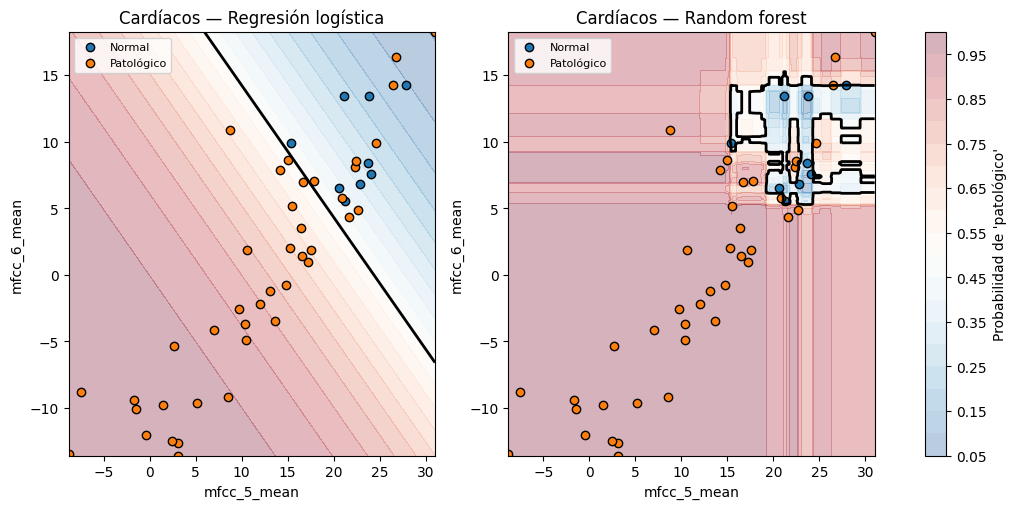

In [18]:
auc_individual = X_hs.apply(lambda col: roc_auc_score(y_hs, col))
DOS = list((auc_individual - 0.5).abs().sort_values(ascending=False).index[:2])
x2 = X_hs[DOS].values
xx, yy = np.meshgrid(np.linspace(x2[:, 0].min(), x2[:, 0].max(), 300),
                     np.linspace(x2[:, 1].min(), x2[:, 1].max(), 300))
grilla = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=DOS)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (nombre, modelo) in zip(axes, [
        ("Regresión logística", make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))),
        ("Random forest", bosque())]):
    modelo.fit(X_hs[DOS], y_hs)
    pp = modelo.predict_proba(grilla)[:, 1].reshape(xx.shape)
    fondo = ax.contourf(xx, yy, pp, levels=20, cmap="RdBu_r", alpha=0.3, vmin=0, vmax=1)
    ax.contour(xx, yy, pp, levels=[0.5], colors="black", linewidths=2)
    for clase, color, etiqueta in [(0, "tab:blue", "Normal"), (1, "tab:orange", "Patológico")]:
        ax.scatter(x2[y_hs == clase, 0], x2[y_hs == clase, 1], c=color, edgecolor="k", label=etiqueta)
    ax.set(xlabel=DOS[0], ylabel=DOS[1], title=f"Cardíacos — {nombre}")
    ax.legend(fontsize=8)
fig.colorbar(fondo, ax=axes, label="Probabilidad de 'patológico'")

La regresión logística solo puede cortar con **una recta**: deja de un lado
a los normales (arriba a la derecha) junto con muchos patológicos que están
cerca de ellos. El bosque corta con **escalones** (cada pregunta es un corte
vertical u horizontal) y puede **encerrar** a los normales en una zona,
dejando patológicos de los dos lados. Esto importa en cardíacos, donde la
clase "patológico" mezcla fenómenos muy distintos (soplos, R3, R4, arritmias)
y no tiene por qué estar toda "del mismo lado" de los normales.

También se ve el costo: el borde del bosque tiene entrantes y huecos para
esquivar grabaciones individuales. Eso es seguir a cada grabación de cerca,
justamente lo que puede volverse memorización (sección 9).

| | Regresión logística | Random forest |
|---|---|---|
| Forma de la frontera | una recta (un plano) | escalones; varias regiones |
| ¿Hay que estandarizar? | sí | no |
| Cómo se interpreta | un peso con signo por feature (odds ratio) | importancia sin signo |
| Freno contra el sobreajuste | regularización (C) | promediar muchos árboles distintos |
| Probabilidades | razonablemente calibradas | fracción de votos; pueden estar corridas (sección 7) |
| Riesgo de "copiar" a la hermana | bajo | mayor con árboles completos (sección 9) |
| Mejor en la tesis en... | pulmonares (frontera lineal alcanza) | cardíacos (por AUC) |

## 11. Los hiperparámetros de la tesis (Tabla 7.1), uno por uno

| Parámetro | Valor | Qué hace | Cómo justificarlo |
|---|---|---|---|
| `n_estimators` | 300 | cantidad de árboles | suficiente para que el resultado se estabilice (sección 5); más árboles no sobreajustan |
| `criterion` | `"gini"` (por defecto) | medida para elegir cada pregunta | estándar; la alternativa (entropía) da resultados casi iguales |
| `max_depth` | sin límite (por defecto) | niveles de preguntas por árbol | el bosque promedia árboles completos; el freno es el promedio |
| `max_features` | `"sqrt"` (por defecto) | features sorteadas por pregunta (≈10) | valor recomendado para clasificación; hace distintos a los árboles |
| `min_samples_leaf` | 1 (por defecto) | mínimo de grabaciones por hoja | por defecto; **pero** con hojas de una grabación `class_weight` casi no actúa (sección 7) y el bosque puede copiar a la hermana (sección 9) |
| `bootstrap` | `True` (por defecto) | cada árbol ve un remuestreo | es lo que hace distintos a los árboles y permite el out-of-bag |
| `class_weight` | `"balanced"` o ninguno (con SMOTE) | peso de cada clase | con árboles completos casi no tiene efecto (sección 7) |
| `random_state` | fijo | semilla del azar | reproducibilidad |

Para el **árbol solo** de la tesis (`DecisionTree`, `max_depth=4`): limitar la
profundidad es su único freno contra el sobreajuste, y la sección 3 muestra
que en cardíacos ni así funciona bien.

**Una propuesta para discutir con tu directora:** fijar de antemano
`min_samples_leaf` en un valor chico mayor que 1 (por ejemplo, 3 o 5) con un
argumento a priori: con 9 normales cardíacos, hojas de una sola grabación
hacen que el peso de las clases no actúe (sección 7). Ojo: eso no resuelve la
fuga entre grabaciones del mismo caso (en pruebas aparte, con
`min_samples_leaf=5` la fuga en pulmonares siguió siendo de ~0,08); para eso,
la respuesta es la validación por caso. Y reportar siempre sensibilidad y
especificidad, no solo el AUC.

## 12. Cómo explicárselo a tu directora (en 5 frases)

1. *"Un árbol de decisión clasifica con preguntas de sí o no sobre las
   features, como un algoritmo clínico; elige cada pregunta para que las
   clases queden lo más separadas posible (impureza de Gini)."*
2. *"Un árbol solo sobreajusta mucho y es inestable; el random forest entrena
   300 árboles, cada uno con un remuestreo de las grabaciones y sorteando qué
   features puede usar en cada pregunta, y promedia sus votos."*
3. *"Promediar árboles distintos reduce la varianza; por eso el bosque
   funciona mucho mejor que un árbol solo, y agregar árboles no lo hace
   sobreajustar."*
4. *"No es lineal: puede armar varias regiones, lo que ayuda en cardíacos,
   donde la clase patológica mezcla fenómenos distintos; fue el de mejor AUC
   ahí."*
5. *"Su probabilidad es la fracción de árboles que votan patológico; con
   pocos normales esa escala queda corrida hacia arriba, y con el umbral 0,5
   casi no reconoce normales: por eso reporto también sensibilidad y
   especificidad."*

## 13. Tu turno

Cambiá `MIN_HOJA` (1, 3, 5, 10, 15) y mirá cómo se mueven las probabilidades
de los normales cardíacos respecto del umbral 0,5. ¿Qué pasa con la
especificidad? ¿Y con el AUC?

AUC              0.78
sensibilidad     0.89
especificidad    0.37


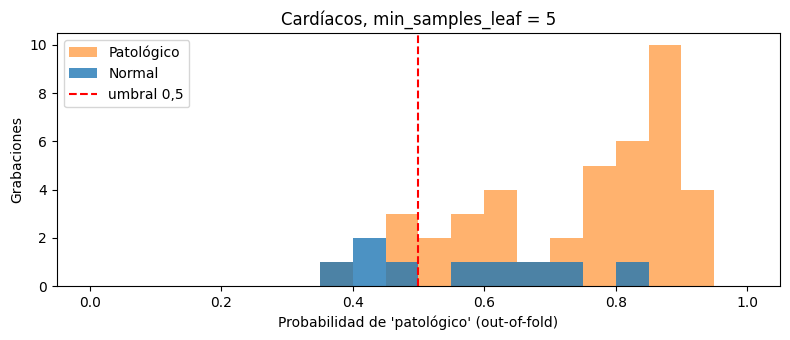

In [19]:
MIN_HOJA = 5

probs = prob_bosque("HS", min_samples_leaf=MIN_HOJA)
p = np.mean(probs, axis=0)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(p[y_hs == 1], bins=bins, alpha=0.6, color="tab:orange", label="Patológico")
ax.hist(p[y_hs == 0], bins=bins, alpha=0.8, color="tab:blue", label="Normal")
ax.axvline(0.5, color="red", ls="--", label="umbral 0,5")
ax.set(xlabel="Probabilidad de 'patológico' (out-of-fold)", ylabel="Grabaciones",
       title=f"Cardíacos, min_samples_leaf = {MIN_HOJA}")
ax.legend()
fig.tight_layout()
print(metricas(y_hs, probs).round(2).to_string())

Lo que deberías ver: con hojas más grandes la escala baja, los normales
empiezan a quedar por debajo de 0,5 y la especificidad sube (de ~0,07 con 1 a
~0,5 con 10). El AUC casi no cambia (~0,78–0,80), porque el **orden** entre
grabaciones se mantiene parecido. Pero con 15 el bosque deja de funcionar
(el AUC baja a ~0,70 y vuelve a decir "patológico" a casi todo): en cada
partición hay solo 40 grabaciones de entrenamiento, y con hojas de al menos
15 los árboles casi no pueden hacer preguntas.

*(Esto es para entender el parámetro, no para elegirlo: el valor no se puede
elegir mirando estos resultados.)*

## Preguntas de control

1. ¿Cómo clasifica un árbol de decisión una grabación nueva? ¿Qué probabilidad da?
2. ¿Qué mide la impureza de Gini y cómo la usa el árbol para elegir cada pregunta?
3. ¿Por qué un árbol sin límite de profundidad acierta todo en entrenamiento y
   funciona mal en validación?
4. ¿Cuáles son las dos fuentes de azar del random forest y para qué sirve cada una?
5. ¿Qué es la predicción out-of-bag? ¿Por qué agregar árboles no produce sobreajuste?
6. ¿Por qué el bosque de la tesis tiene buen AUC pero especificidad casi nula en
   cardíacos? ¿Por qué `class_weight` no lo corrige?
7. ¿Qué limitaciones tiene la importancia de las features del bosque?
8. ¿Por qué un bosque con árboles completos puede aprovechar más la fuga entre
   grabaciones del mismo caso que una regresión logística?
9. En cardíacos no hay fuga medible, pero el AUC del bosque cae mucho al
   validar por caso. ¿Por qué?

## Respuestas a las preguntas de control

*(Intentá responder antes de leer.)*

**1.** La hace bajar por el árbol respondiendo cada pregunta (¿esta feature
es menor o igual a tal valor?) hasta llegar a una hoja. La probabilidad de
"patológico" es la proporción de grabaciones patológicas de entrenamiento que
hay en esa hoja.

**2.** Mide qué tan mezcladas están las clases en una caja: 0 si es pura, 0,5
si es mitad y mitad. Para cada pregunta, el árbol prueba todas las features y
todos los cortes, y elige el que deja los dos lados más puros (el que más
baja la impureza promedio, ponderada por cuántas grabaciones van a cada lado).

**3.** Porque sigue preguntando hasta que cada hoja es pura, así que termina
armando reglas a medida de cada grabación de entrenamiento (memoriza). Esas
reglas no se repiten en grabaciones nuevas: es sobreajuste, varianza alta.

**4.** Cada árbol se entrena con un remuestreo bootstrap de las grabaciones
(*bagging*), y en cada pregunta solo puede elegir entre unas pocas features
sorteadas (`max_features`). Las dos sirven para que los árboles sean
distintos entre sí: si fueran todos iguales, promediarlos no reduciría la
varianza.

**5.** Es la predicción de cada grabación hecha solo con los árboles que no
la vieron (los que no la tenían en su remuestreo): una validación gratis.
Agregar árboles no sobreajusta porque no hace más complejo a ningún árbol:
solo promedia más opiniones, y el promedio se estabiliza.

**6.** Porque su probabilidad es la fracción de árboles que votan
"patológico", y con 41 patológicos y 9 normales esa fracción queda alta para
casi todos: los normales quedan por debajo de los patológicos (buen orden,
buen AUC) pero por encima de 0,5 (mala especificidad con ese umbral).
`class_weight` no lo corrige porque, con árboles completos, las hojas son
puras y votan lo mismo pese lo que pese cada clase; el peso solo cambia qué
preguntas se eligen.

**7.** No tiene signo; las features correlacionadas se reparten la
importancia; se calcula con los datos de entrenamiento, así que incluye lo
que el bosque usa para memorizar; y es asociación, no causa. La importancia
por permutación sobre datos de validación es más confiable.

**8.** Porque con árboles completos cada hoja contiene una o muy pocas
grabaciones: una grabación nueva casi idéntica a su hermana cae en la misma
hoja y "copia" su etiqueta, como si buscara la grabación más parecida. La
regresión logística ajusta una única frontera lineal para todos los datos y
no puede seguir a una grabación individual. En pulmonares se vio: fuga real
de ~0,09 con el bosque contra ~0,02 con la regresión logística.

**9.** Porque en cardíacos hay solo dos casos normales (6 y 3 grabaciones).
Al dejar uno afuera, el bosque se entrena con 3 o 6 normales contra 41
patológicos, y su escala de probabilidades se corre hacia arriba justo para
esos normales: quedan mezclados con los patológicos y el AUC cae. Es un
efecto del esquema de validación (y de la escala del bosque), no
memorización: los pseudo-casos caen igual que el caso real.